In [16]:
import pandas as pd

# Load the Excel file
file_path = "Downloads/Online Retail.xlsx"
df = pd.read_excel(file_path)

# Show initial data shape and a preview
df_shape_before = df.shape
df_preview = df.head()

df_shape_before, df_preview
print(df.head())

((541909, 9),
   InvoiceNo StockCode                          Description  Quantity  \
 0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
 1    536365     71053                  WHITE METAL LANTERN         6   
 2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
 3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
 4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
 
           InvoiceDate  UnitPrice  CustomerID         Country  Rollno  
 0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom   41030  
 1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   41056  
 2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom   41109  
 3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   41086  
 4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom   41079  )

In [17]:
# Load only the first 500 rows to inspect the structure
df_sample = pd.read_excel(file_path, nrows=500)
df_sample.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Rollno'],
      dtype='object')

In [18]:
# Load full data but only required columns for cleaning and filtering
use_columns = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
               'UnitPrice', 'CustomerID', 'Country', 'Rollno']
df_full = pd.read_excel(file_path, usecols=use_columns)

# Step 1: Filter only for roll number 41038
df_roll = df_full[df_full['Rollno'] == 41038]

# Step 2: Drop rows with missing StockCode, Description, or CustomerID
before_cleaning = df_roll.shape[0]
df_cleaned = df_roll.dropna(subset=['StockCode', 'Description', 'CustomerID'])
after_cleaning = df_cleaned.shape[0]

# Step 3: Calculate number of rows removed
rows_removed = before_cleaning - after_cleaning

before_cleaning, after_cleaning, rows_removed

(13698, 10070, 3628)

In [41]:
import pandas as pd

# Use your cleaned DataFrame from before
df = df_cleaned.copy()

### ---------- Summary Set 1 ---------- ###

# 1. Count unique customers
unique_customers = df['CustomerID'].nunique()

# 2. Count unique products (StockCode)
unique_products = df['StockCode'].nunique()

# 3. Calculate Revenue (Quantity * UnitPrice)
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# 4. Revenue by customer
revenue_by_customer = df.groupby('CustomerID')['Revenue'].sum().sort_values(ascending=False)

# 5. Revenue by product
revenue_by_product = df.groupby('StockCode')['Revenue'].sum().sort_values(ascending=False)

# 6. Top 25 Customer-Product by revenue
top_25_cp_revenue = (
    df.groupby(['CustomerID', 'StockCode'])['Revenue']
    .sum()
    .reset_index()
    .sort_values(by='Revenue', ascending=False)
    .head(25)
)

# 7. Top 25 Customer-Product by quantity
top_25_cp_quantity = (
    df.groupby(['CustomerID', 'StockCode'])['Quantity']
    .sum()
    .reset_index()
    .sort_values(by='Quantity', ascending=False)
    .head(25)
)

# 8. Unique top Customer-Product combinations (from both top 10s)
top_cp_combined = pd.concat([
    top_25_cp_revenue[['CustomerID', 'StockCode']],
    top_25_cp_quantity[['CustomerID', 'StockCode']]
]).drop_duplicates().reset_index(drop=True)

In [24]:
### ---------- Data Preparation ---------- ###

# 1. Create price band column
def price_band(price):
    if price < 5:
        return 'Low'
    elif 5 <= price <= 10:
        return 'Medium'
    else:
        return 'High'

df['PriceBand'] = df['UnitPrice'].apply(price_band)

# 2. Average price at product-customer level
df['AvgPrice_CustProduct'] = df.groupby(['CustomerID', 'StockCode'])['UnitPrice'].transform('mean')

# 3. Extract Year, Month, Week, Day of Week
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['Week'] = df['InvoiceDate'].dt.isocalendar().week
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()

# 4. Logical column for returns
df['IsReturn'] = df['InvoiceNo'].astype(str).str.startswith('C')

# 5. Create TransactionType column
df['TransactionType'] = df['IsReturn'].apply(lambda x: 'Return' if x else 'Sale')

### ---------- Summary Output ---------- ###
print("Unique Customers:", unique_customers)
print("Unique Products:", unique_products)
print("\nTop 5 Revenue by Customer:\n", revenue_by_customer.head())
print("\nTop 5 Revenue by Product:\n", revenue_by_product.head())
print("\nTop 5 Customer-Product by Revenue:\n", top_25_cp_revenue.head())
print("\nTop 5 Customer-Product by Quantity:\n", top_25_cp_quantity.head())
print("\nCombined Top Customer-Product Pairs:\n", top_cp_combined.head())

Unique Customers: 2455
Unique Products: 95

Top 5 Revenue by Customer:
 CustomerID
14646.0    10456.38
15769.0     4679.00
17511.0     3983.09
17450.0     3967.12
12415.0     3669.12
Name: Revenue, dtype: float64

Top 5 Revenue by Product:
 StockCode
23203    36607.98
22385    15115.88
20750    12169.10
82600    12024.08
21217     9098.70
Name: Revenue, dtype: float64

Top 5 Customer-Product by Revenue:
       CustomerID StockCode  Revenue
3949     15769.0     22385  4679.00
5655     17450.0     82600  3120.12
6262     17949.0     23171  2552.00
4582     16422.0     17003  2188.80
757      12931.0     23203  2058.50

Top 5 Customer-Product by Quantity:
       CustomerID StockCode  Quantity
4582     16422.0     17003     10077
3949     15769.0     22385      2700
6262     17949.0     23171      1760
5605     17414.0     17003      1440
2614     14609.0     17003      1440

Combined Top Customer-Product Pairs:
    CustomerID StockCode
0     15769.0     22385
1     17450.0     82600
2    

In [47]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Rollno,Revenue
89,536378,20723,STRAWBERRY CHARLOTTE BAG,10,2010-12-01 09:37:00,0.85,14688.0,United Kingdom,41038,8.50
120,536381,37444A,YELLOW BREAKFAST CUP AND SAUCER,1,2010-12-01 09:41:00,2.95,15311.0,United Kingdom,41038,2.95
465,536408,22371,AIRLINE BAG VINTAGE TOKYO 78,4,2010-12-01 11:41:00,4.25,14307.0,United Kingdom,41038,17.00
536,536409,20723,STRAWBERRY CHARLOTTE BAG,1,2010-12-01 11:45:00,0.85,17908.0,United Kingdom,41038,0.85
621,536412,20750,RED RETROSPOT MINI CASES,1,2010-12-01 11:49:00,7.95,17920.0,United Kingdom,41038,7.95


In [25]:
print(df.columns)


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Rollno', 'Revenue', 'PriceBand',
       'AvgPrice_CustProduct', 'Year', 'Month', 'Week', 'DayOfWeek',
       'IsReturn', 'TransactionType'],
      dtype='object')


In [26]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Rollno,Revenue,PriceBand,AvgPrice_CustProduct,Year,Month,Week,DayOfWeek,IsReturn,TransactionType
89,536378,20723,STRAWBERRY CHARLOTTE BAG,10,2010-12-01 09:37:00,0.85,14688.0,United Kingdom,41038,8.50,Low,0.85,2010,12,48,Wednesday,False,Sale
120,536381,37444A,YELLOW BREAKFAST CUP AND SAUCER,1,2010-12-01 09:41:00,2.95,15311.0,United Kingdom,41038,2.95,Low,2.31,2010,12,48,Wednesday,False,Sale
465,536408,22371,AIRLINE BAG VINTAGE TOKYO 78,4,2010-12-01 11:41:00,4.25,14307.0,United Kingdom,41038,17.00,Low,4.25,2010,12,48,Wednesday,False,Sale
536,536409,20723,STRAWBERRY CHARLOTTE BAG,1,2010-12-01 11:45:00,0.85,17908.0,United Kingdom,41038,0.85,Low,0.85,2010,12,48,Wednesday,False,Sale
621,536412,20750,RED RETROSPOT MINI CASES,1,2010-12-01 11:49:00,7.95,17920.0,United Kingdom,41038,7.95,Medium,7.95,2010,12,48,Wednesday,False,Sale


In [27]:
# Ensure Revenue column is already created
df['Revenue'] = df['Quantity'] * df['UnitPrice']

### 1. Total Revenue by Country
revenue_by_country = df.groupby('Country')['Revenue'].sum().reset_index()
revenue_by_country['RevenueRank'] = revenue_by_country['Revenue'].rank(ascending=False, method='dense')

### 2. Total Order Quantity by Country
quantity_by_country = df.groupby('Country')['Quantity'].sum().reset_index()
quantity_by_country['QuantityRank'] = quantity_by_country['Quantity'].rank(ascending=False, method='dense')

### 3. Average Order Value by Country
# Step 1: calculate total revenue and number of invoices per country
invoice_stats = df.groupby(['Country', 'InvoiceNo'])['Revenue'].sum().reset_index()
avg_order_value = invoice_stats.groupby('Country')['Revenue'].mean().reset_index()
avg_order_value.columns = ['Country', 'AvgOrderValue']

### Merge all three into one DataFrame
summary_country = revenue_by_country.merge(quantity_by_country, on='Country').merge(avg_order_value, on='Country')

### Display
print(summary_country.sort_values(by='Revenue', ascending=False).head(10))

           Country    Revenue  RevenueRank  Quantity  QuantityRank  \
31  United Kingdom  161550.21          1.0    111736           1.0   
20     Netherlands   10648.44          2.0      6472           2.0   
11          France    5621.21          3.0      2798           3.0   
12         Germany    5248.75          4.0      2342           5.0   
8             EIRE    5047.61          5.0      2655           4.0   
0        Australia    3882.21          6.0      1945           6.0   
17           Japan    1631.04          7.0       424          11.0   
28     Switzerland    1421.45          8.0       697           7.0   
2          Belgium    1004.35          9.0       525           8.0   
21          Norway     978.04         10.0       504           9.0   

    AvgOrderValue  
31      28.203598  
20     247.638140  
11      35.803885  
12      36.963028  
8       40.380880  
0      215.678333  
17     271.840000  
28      52.646296  
2       28.695714  
21      69.860000  


In [28]:
### STEP 1: Identify Top Customer-Product Pairs (based on Revenue)
top_cp_revenue = (
    df.groupby(['CustomerID', 'StockCode'])['Revenue']
    .sum()
    .reset_index()
    .sort_values(by='Revenue', ascending=False)
    .head(25)
)

### STEP 2: For each top pair, count how many orders were above the AvgPrice_CustProduct

# Merge top customer-product pairs back with full data
df_top = df.merge(top_cp_revenue[['CustomerID', 'StockCode']], on=['CustomerID', 'StockCode'])

# Flag where UnitPrice > AvgPrice_CustProduct
df_top['AboveAvgPrice'] = df_top['UnitPrice'] > df_top['AvgPrice_CustProduct']

# Count number of orders above average price per (Customer, Product)
orders_above_avg = df_top.groupby(['CustomerID', 'StockCode'])['AboveAvgPrice'].sum().reset_index()
orders_above_avg.columns = ['CustomerID', 'StockCode', 'OrdersAboveAvgPrice']

### STEP 3: Identify customer with highest return value

# Filter returns
returns_df = df[df['IsReturn'] == True]

# Total return revenue per customer
return_value_by_customer = returns_df.groupby('CustomerID')['Revenue'].sum().reset_index()
top_return_customer = return_value_by_customer.sort_values(by='Revenue', ascending=False).head(1)

### STEP 4: Calculate % of orders where price > average price (for all transactions)

df['AboveAvgPrice'] = df['UnitPrice'] > df['AvgPrice_CustProduct']
total_orders = df.shape[0]
above_avg_orders = df['AboveAvgPrice'].sum()
percentage_above_avg = (above_avg_orders / total_orders) * 100

### STEP 5: Create a product vs weekday sales table

# Group by product and day of week, sum Revenue
weekday_sales = df.groupby(['StockCode', 'DayOfWeek'])['Revenue'].sum().unstack(fill_value=0)

# Reorder days (optional)
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_sales = weekday_sales.reindex(columns=weekday_order)

### Output Summaries

print("\n--- Orders Above Average Price per Top Customer-Product ---")
print(orders_above_avg.head())

print("\n--- Customer with Highest Return Value ---")
print(top_return_customer)

print("\n--- Percentage of Orders Above Avg Price ---")
print(f"{percentage_above_avg:.2f}%")

print("\n--- Weekday Sales by Product (sample) ---")
print(weekday_sales.head())



--- Orders Above Average Price per Top Customer-Product ---
   CustomerID StockCode  OrdersAboveAvgPrice
0     12415.0     21217                    0
1     12678.0     23203                    0
2     12753.0     20750                    3
3     12753.0     21217                    0
4     12931.0     23203                    0

--- Customer with Highest Return Value ---
     CustomerID  Revenue
102     16150.0    -0.85

--- Percentage of Orders Above Avg Price ---
5.74%

--- Weekday Sales by Product (sample) ---
DayOfWeek  Monday  Tuesday  Wednesday  Thursday  Friday  Saturday  Sunday
StockCode                                                                
16016       58.65   331.85     164.85    197.20  255.00       NaN   45.90
16049       34.56    15.12      17.28     15.12    0.00       NaN    0.00
17003      769.20   667.31    2091.80   1036.84  506.52       NaN  735.58
17174        0.00     0.00       0.00      2.10    0.00       NaN    1.68
20702       38.25    97.75     170.0

In [29]:
pd.set_option('display.max_columns', None)  # Show all columns
print(df.head())  # Or df.tail(), df.sample(), etc.

    InvoiceNo StockCode                      Description  Quantity  \
89     536378     20723         STRAWBERRY CHARLOTTE BAG        10   
120    536381    37444A  YELLOW BREAKFAST CUP AND SAUCER         1   
465    536408     22371     AIRLINE BAG VINTAGE TOKYO 78         4   
536    536409     20723         STRAWBERRY CHARLOTTE BAG         1   
621    536412     20750         RED RETROSPOT MINI CASES         1   

            InvoiceDate  UnitPrice  CustomerID         Country  Rollno  \
89  2010-12-01 09:37:00       0.85     14688.0  United Kingdom   41038   
120 2010-12-01 09:41:00       2.95     15311.0  United Kingdom   41038   
465 2010-12-01 11:41:00       4.25     14307.0  United Kingdom   41038   
536 2010-12-01 11:45:00       0.85     17908.0  United Kingdom   41038   
621 2010-12-01 11:49:00       7.95     17920.0  United Kingdom   41038   

     Revenue PriceBand  AvgPrice_CustProduct  Year  Month  Week  DayOfWeek  \
89      8.50       Low                  0.85  2010     1

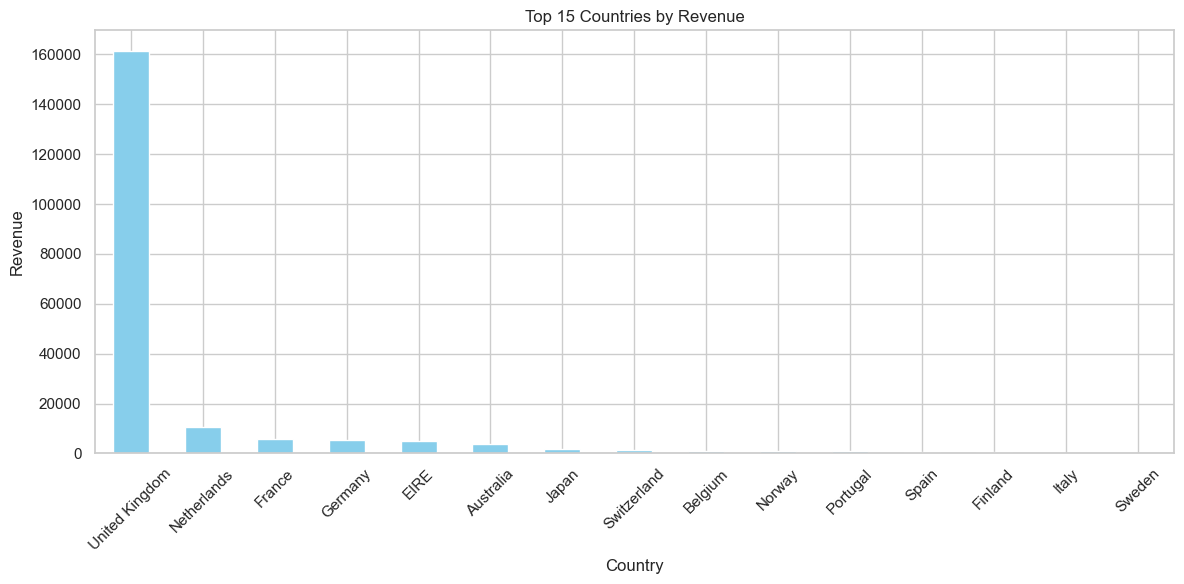

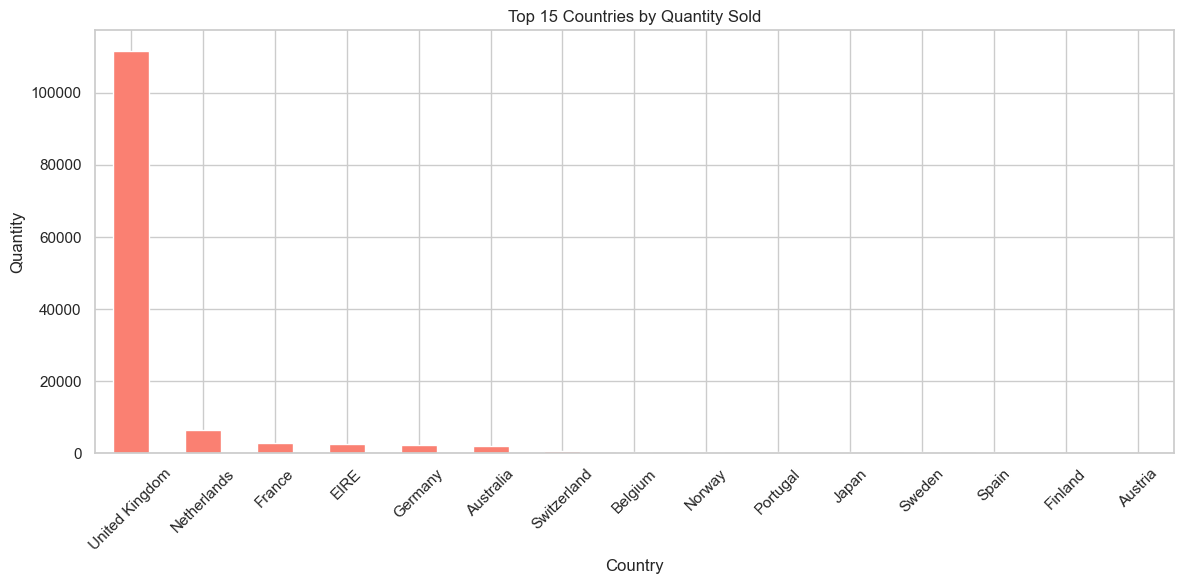

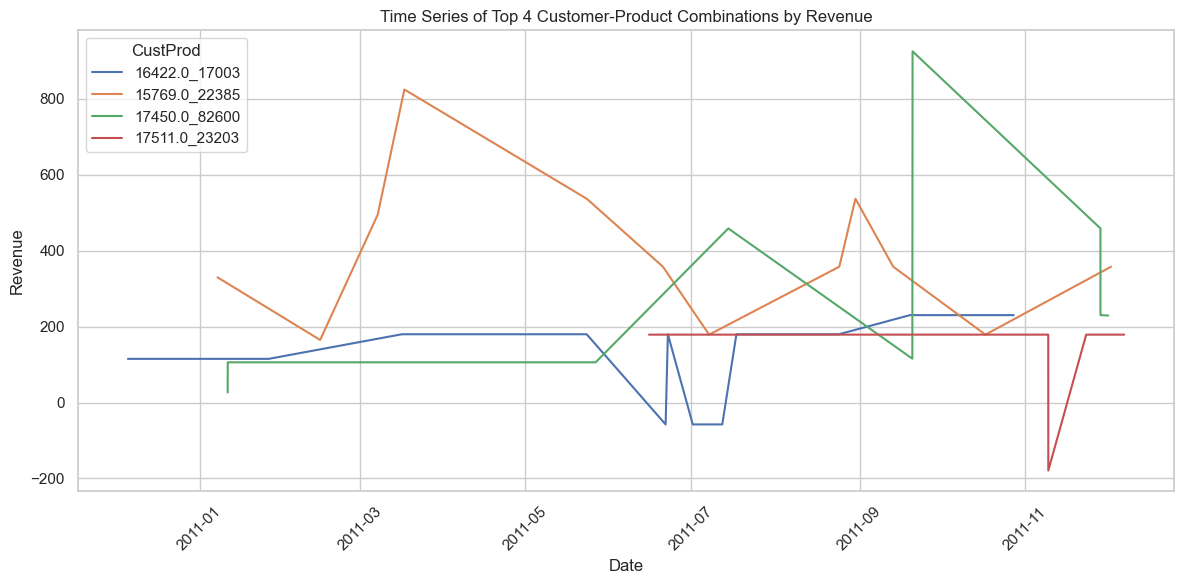

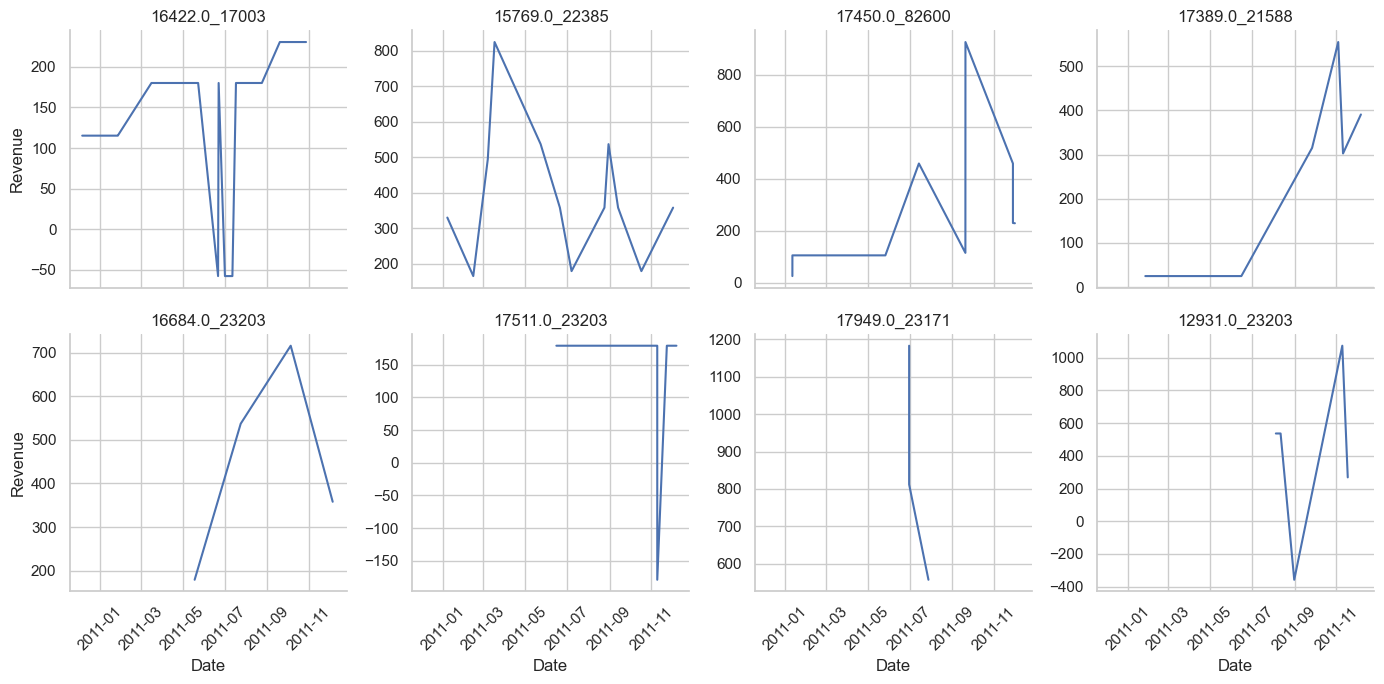

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set styles for better visuals
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# --- Plot 1: Revenue by Country ---
revenue_by_country_plot = df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(15)

plt.figure()
revenue_by_country_plot.plot(kind='bar', color='skyblue')
plt.title('Top 15 Countries by Revenue')
plt.ylabel('Revenue')
plt.xlabel('Country')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 2: Quantity by Country ---
quantity_by_country_plot = df.groupby('Country')['Quantity'].sum().sort_values(ascending=False).head(15)

plt.figure()
quantity_by_country_plot.plot(kind='bar', color='salmon')
plt.title('Top 15 Countries by Quantity Sold')
plt.ylabel('Quantity')
plt.xlabel('Country')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Prepare Top 8 Customer-Product Combinations by Revenue ---
top_cp_rev_8 = (
    df.groupby(['CustomerID', 'StockCode'])['Revenue']
    .sum()
    .reset_index()
    .sort_values(by='Revenue', ascending=False)
    .head(8)
)

# Merge to get transaction-level data
df_top8 = df.merge(top_cp_rev_8[['CustomerID', 'StockCode']], on=['CustomerID', 'StockCode'])

# Convert to datetime (if not already done)
df_top8['InvoiceDate'] = pd.to_datetime(df_top8['InvoiceDate'])

# Create an ID for combination
df_top8['CustProd'] = df_top8['CustomerID'].astype(str) + '_' + df_top8['StockCode'].astype(str)

# --- Plot 3: Time series of TOP 4 combinations (single plot) ---
top4_ids = df_top8['CustProd'].value_counts().head(4).index.tolist()
df_top4 = df_top8[df_top8['CustProd'].isin(top4_ids)]

plt.figure()
sns.lineplot(data=df_top4, x='InvoiceDate', y='Revenue', hue='CustProd', estimator='sum', errorbar=None)
plt.title('Time Series of Top 4 Customer-Product Combinations by Revenue')
plt.ylabel('Revenue')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Plot 4: Time series of TOP 8 combinations (faceted plot) ---
g = sns.FacetGrid(df_top8, col='CustProd', col_wrap=4, height=3.5, sharey=False)
g.map_dataframe(sns.lineplot, x='InvoiceDate', y='Revenue', estimator='sum', errorbar=None)
g.set_titles("{col_name}")
g.set_axis_labels("Date", "Revenue")
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(45)
plt.tight_layout()
plt.show()

In [33]:
def generate_customer_summary(df):
    import pandas as pd

    # Ensure dates are in datetime format
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

    # Calculate Revenue
    df['Revenue'] = df['Quantity'] * df['UnitPrice']

    # Group by CustomerID and calculate summary metrics
    summary = df.groupby('CustomerID').agg(
        TotalSpent=('Revenue', 'sum'),
        NumOrders=('InvoiceNo', 'nunique'),
        FirstPurchase=('InvoiceDate', 'min'),
        LastPurchase=('InvoiceDate', 'max')
    ).reset_index()

    # Define Value Bands (customize as needed)
    conditions = [
        summary['TotalSpent'] >= 10000,   # High Value
        summary['TotalSpent'] >= 3000     # Medium Value
    ]
    choices = ['High Value', 'Medium Value']
    summary['CustomerClass'] = pd.cut(
        summary['TotalSpent'],
        bins=[-float('inf'), 2999.99, 9999.99, float('inf')],
        labels=['Low Value', 'Medium Value', 'High Value']
    )

    return summary


In [34]:
customer_summary = generate_customer_summary(df)
print(customer_summary.head())


   CustomerID  TotalSpent  NumOrders       FirstPurchase        LastPurchase  \
0     12347.0      152.20          4 2011-04-07 10:43:00 2011-10-31 12:25:00   
1     12349.0       32.70          1 2011-11-21 09:51:00 2011-11-21 09:51:00   
2     12354.0       35.80          1 2011-04-21 13:11:00 2011-04-21 13:11:00   
3     12357.0      195.96          1 2011-11-06 16:07:00 2011-11-06 16:07:00   
4     12359.0      126.95          3 2011-02-07 14:51:00 2011-10-13 12:47:00   

  CustomerClass  
0     Low Value  
1     Low Value  
2     Low Value  
3     Low Value  
4     Low Value  


In [35]:
customer_summary.head()

,CustomerID,TotalSpent,NumOrders,FirstPurchase,LastPurchase,CustomerClass
0,12347.0,152.20,4,2011-04-07 10:43:00,2011-10-31 12:25:00,Low Value
1,12349.0,32.70,1,2011-11-21 09:51:00,2011-11-21 09:51:00,Low Value
2,12354.0,35.80,1,2011-04-21 13:11:00,2011-04-21 13:11:00,Low Value
3,12357.0,195.96,1,2011-11-06 16:07:00,2011-11-06 16:07:00,Low Value
4,12359.0,126.95,3,2011-02-07 14:51:00,2011-10-13 12:47:00,Low Value


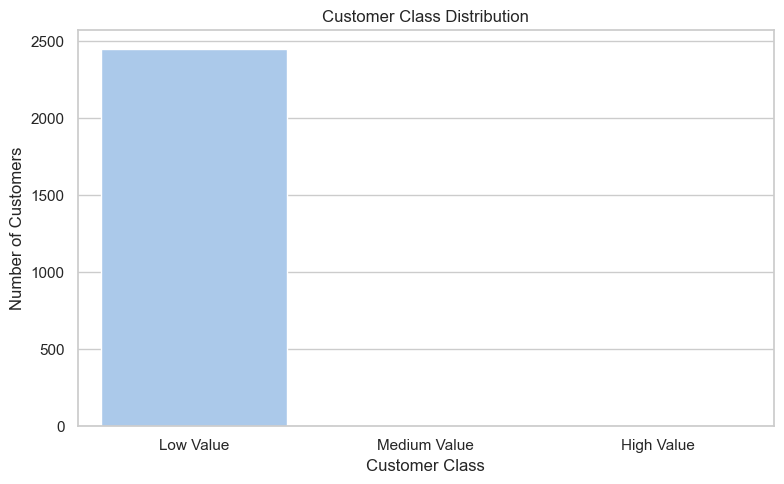

In [44]:

# Generate the summary function again
def generate_customer_summary(df):
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
    df['Revenue'] = df['Quantity'] * df['UnitPrice']
    summary = df.groupby('CustomerID').agg(
        TotalSpent=('Revenue', 'sum'),
        NumOrders=('InvoiceNo', 'nunique'),
        FirstPurchase=('InvoiceDate', 'min'),
        LastPurchase=('InvoiceDate', 'max')
    ).reset_index()

    summary['CustomerClass'] = pd.cut(
        summary['TotalSpent'],
        bins=[-float('inf'), 2999.99, 9999.99, float('inf')],
        labels=['Low Value', 'Medium Value', 'High Value']
    )
    return summary

# Generate the summary
customer_summary = generate_customer_summary(df)

# Plot customer class distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=customer_summary, x='CustomerClass', hue='CustomerClass', palette='pastel', legend = False)
plt.title('Customer Class Distribution')
plt.xlabel('Customer Class')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()
